In [7]:
# ============================================================================
# Proyecto RADA-GAS — Script completo
# Detección y clasificación de gases con robustez ante la deriva temporal
# Versión 2.0 — Ejecutar de arriba a abajo en Google Colab
#
# Etapa A — Clasificación del tipo de gas (UCI Gas Sensor Array Drift)
# Etapa B — Detección de fuga de GLP (Zenodo 6616632)
#
# Hallazgo central: la exactitud intra-sesión (0.9914) y la exactitud entre
# sesiones (0.2656–0.5711) difieren en más de 40 puntos. Esa brecha cuantifica
# el drift de sensor y justifica la recalibración periódica.
# ============================================================================

In [8]:
# ============================================================
# CELDA 2 — Setup: dependencias, semillas y directorio de trabajo
# ============================================================
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'openpyxl', 'joblib'],
               check=False)

import os, glob, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import stats

from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     LeaveOneGroupOut)
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score,
                             recall_score, precision_score)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 120)

SEMILLA = 42
np.random.seed(SEMILLA)

DIR = '/content/RADA-GAS'
os.makedirs(DIR, exist_ok=True)
os.chdir(DIR)
print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/RADA-GAS


In [9]:
# ============================================================
# CELDA 3 — Descarga de datos (UCI + Zenodo 6616632)
# ============================================================
UCI_URL = "https://archive.ics.uci.edu/static/public/224/gas+sensor+array+drift+dataset.zip"
if not os.path.exists('uci.zip'):
    urllib.request.urlretrieve(UCI_URL, 'uci.zip')
if not os.path.exists('uci'):
    with zipfile.ZipFile('uci.zip') as z:
        z.extractall('uci')

BASE_ZENODO = "https://zenodo.org/records/6616632/files/"
for f in ['lpg_sensor.xlsx', 'cng_sensor.xlsx', 'co_sensor.xlsx',
          'smoke_sensor.xlsx', 'flame_sensor.xlsx']:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE_ZENODO + f + "?download=1", f)

print("Archivos listos:", sorted(os.listdir('.')))

Archivos listos: ['cng_sensor.xlsx', 'co_sensor.xlsx', 'drift_por_batch.png', 'flame_sensor.xlsx', 'importancia_features.csv', 'lpg_sensor.xlsx', 'matriz_confusion.png', 'modelo_gas_extratrees.pkl', 'serie_glp.png', 'smoke_sensor.xlsx', 'uci', 'uci.zip']


In [10]:
# ============================================================
# CELDA 4 — Utilidades (definidas una sola vez, usadas en todo el script)
# ============================================================

def cargar_batch_limpio(path):
    """Parsea un .dat en formato LibSVM (clase;conc idx:val ...) a DataFrame."""
    records = []
    with open(path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            clase_info = parts[0].split(';')
            clase = int(clase_info[0])
            concentracion = float(clase_info[1]) if len(clase_info) > 1 else 0.0
            features = {'clase': clase, 'concentracion': concentracion}
            for item in parts[1:]:
                if ':' in item:
                    idx, val = item.split(':')
                    features[f'f{int(idx)-1}'] = float(val)
            records.append(features)
    return pd.DataFrame(records).fillna(0.0)


def cargar_todos_los_batches():
    """Devuelve dict {batchN: DataFrame} para los 10 batches de UCI."""
    batches = {}
    for i in range(1, 11):
        nombre = f'batch{i}'
        for candidato in [f'uci/Dataset/{nombre}.dat',
                          f'/content/sample_data/uci/Dataset/{nombre}.dat']:
            if os.path.exists(candidato):
                batches[nombre] = cargar_batch_limpio(candidato)
                break
    return batches


def ic_exactitud(y_true, y_pred, conf=0.95):
    """IC normal (Wald) para la exactitud. Devuelve (acc, lo, hi)."""
    acc = accuracy_score(y_true, y_pred)
    n = len(y_true)
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    margen = z * np.sqrt(acc * (1 - acc) / n)
    return acc, max(0, acc - margen), min(1, acc + margen)


def wilson(k, n, conf=0.95):
    """IC de Wilson para una proporción. Devuelve (p, lo, hi)."""
    if n == 0:
        return (np.nan, np.nan, np.nan)
    p = k / n
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return p, max(0, centro - margen), min(1, centro + margen)


batches = cargar_todos_los_batches()
FEATS = [c for c in batches['batch1'].columns if c.startswith('f')]
print({k: v.shape for k, v in batches.items()})
print(f"Features: {len(FEATS)}")

{'batch1': (445, 130), 'batch2': (1244, 130), 'batch3': (1586, 130), 'batch4': (161, 130), 'batch5': (197, 130), 'batch6': (2300, 130), 'batch7': (3613, 130), 'batch8': (294, 130), 'batch9': (470, 130), 'batch10': (3600, 130)}
Features: 128


In [11]:
# ============================================================
# CELDA 5 — Partición: train = batches 1..9, test = batch10
# ============================================================
BATCHS_TRAIN = [b for b in sorted(batches) if b != 'batch10']

df_train = pd.concat([batches[b] for b in BATCHS_TRAIN], ignore_index=True)
df_test  = batches['batch10']

X_train, y_train = df_train[FEATS], df_train['clase']
X_test,  y_test  = df_test[FEATS],  df_test['clase']

print(f"Train: {len(X_train)} filas ({', '.join(BATCHS_TRAIN)})")
print(f"Test : {len(X_test)} filas (batch10)")
print(f"Clases train: {sorted(y_train.unique().tolist())}")
print(f"Clases test : {sorted(y_test.unique().tolist())}")

Train: 10310 filas (batch1, batch2, batch3, batch4, batch5, batch6, batch7, batch8, batch9)
Test : 3600 filas (batch10)
Clases train: [1, 2, 3, 4, 5, 6]
Clases test : [1, 2, 3, 4, 5, 6]


In [12]:
# ============================================================
# CELDA 6 — Comparación de modelos (6 clases)
# ============================================================
modelos = {
    'RandomForest 400': RandomForestClassifier(
        n_estimators=400, max_features='sqrt', min_samples_leaf=2,
        random_state=SEMILLA, class_weight='balanced', n_jobs=-1),
    'ExtraTrees 400': ExtraTreesClassifier(
        n_estimators=400, max_features='sqrt', min_samples_leaf=2,
        random_state=SEMILLA, class_weight='balanced', n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.08, max_leaf_nodes=31,
        random_state=SEMILLA),
}

filas = []
for nombre, m in modelos.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    acc_i, lo_i, hi_i = ic_exactitud(y_test, p)
    filas.append({'modelo': nombre,
                  'exactitud': round(acc_i, 4),
                  'IC95_inf': round(lo_i, 4),
                  'IC95_sup': round(hi_i, 4),
                  'macro_f1': round(f1_score(y_test, p, average='macro'), 4)})

tabla_modelos = pd.DataFrame(filas).sort_values('exactitud', ascending=False)
print(tabla_modelos.to_string(index=False))

              modelo  exactitud  IC95_inf  IC95_sup  macro_f1
      ExtraTrees 400     0.6411    0.6254    0.6568    0.6401
    RandomForest 400     0.6017    0.5857    0.6177    0.6008
HistGradientBoosting     0.5903    0.5742    0.6063    0.5925


In [13]:
# ============================================================
# CELDA 7 — ETAPA A: modelo final ExtraTrees 400
# ============================================================
print("#" * 55)
print("# ETAPA A — MODELO FINAL: ExtraTrees 400")
print("#" * 55)

modelo_final = ExtraTreesClassifier(
    n_estimators=400, max_features='sqrt', min_samples_leaf=2,
    random_state=SEMILLA, class_weight='balanced', n_jobs=-1)
modelo_final.fit(X_train, y_train)
pred_final = modelo_final.predict(X_test)

acc, lo, hi = ic_exactitud(y_test, pred_final)
macro_f1 = f1_score(y_test, pred_final, average='macro')

print(f"Entrenamiento: {', '.join(BATCHS_TRAIN)} ({len(X_train)} filas)")
print(f"Prueba       : batch10 ({len(X_test)} filas)\n")
print(f"Exactitud : {acc:.4f}  (IC 95%: {lo:.4f} – {hi:.4f})")
print(f"Macro-F1  : {macro_f1:.4f}\n")
print(classification_report(y_test, pred_final, digits=4))

imp = pd.DataFrame({'feature': FEATS,
                    'importancia': modelo_final.feature_importances_}
                   ).sort_values('importancia', ascending=False)
print("Top 15 features:")
print(imp.head(15).to_string(index=False))
imp.to_csv('importancia_features.csv', index=False)

joblib.dump(modelo_final, 'modelo_gas_extratrees.pkl')
print("\nGuardado: modelo_gas_extratrees.pkl")


#######################################################
# ETAPA A — MODELO FINAL: ExtraTrees 400
#######################################################
Entrenamiento: batch1, batch2, batch3, batch4, batch5, batch6, batch7, batch8, batch9 (10310 filas)
Prueba       : batch10 (3600 filas)

Exactitud : 0.6411  (IC 95%: 0.6254 – 0.6568)
Macro-F1  : 0.6401

              precision    recall  f1-score   support

           1     0.6829    0.4200    0.5201       600
           2     0.6748    0.6883    0.6815       600
           3     0.9281    0.6667    0.7759       600
           4     0.5223    0.5467    0.5342       600
           5     0.6399    0.7583    0.6941       600
           6     0.5418    0.7667    0.6349       600

    accuracy                         0.6411      3600
   macro avg     0.6650    0.6411    0.6401      3600
weighted avg     0.6650    0.6411    0.6401      3600

Top 15 features:
feature  importancia
    f10     0.021455
     f8     0.021253
    f67     0.018962


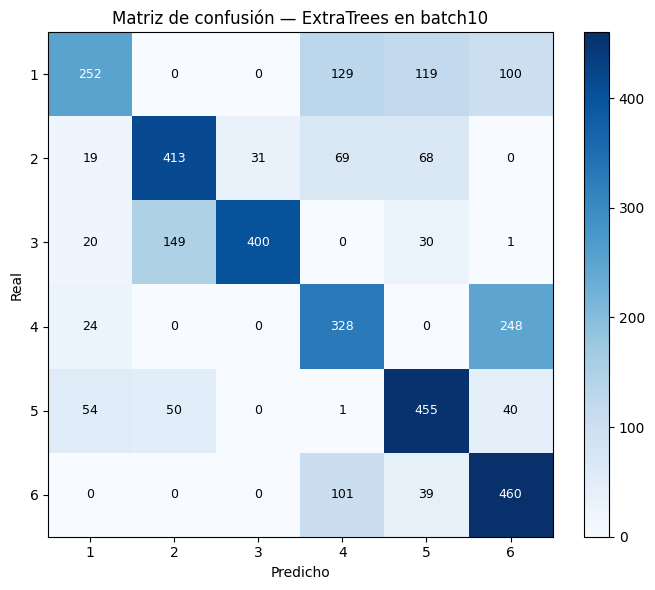


Top 10 confusiones:
 real  predicho   n
    4         6 248
    3         2 149
    1         4 129
    1         5 119
    6         4 101
    1         6 100
    2         4  69
    2         5  68
    5         1  54
    5         2  50


In [14]:
# ============================================================
# CELDA 8 — Matriz de confusión y pares más confundidos
# ============================================================
cm = confusion_matrix(y_test, pred_final)
etiquetas = sorted(y_test.unique())

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(etiquetas))); ax.set_xticklabels(etiquetas)
ax.set_yticks(range(len(etiquetas))); ax.set_yticklabels(etiquetas)
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title('Matriz de confusión — ExtraTrees en batch10')
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig('matriz_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

pares = []
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        if i != j and cm[i, j] > 0:
            pares.append({'real': etiquetas[i], 'predicho': etiquetas[j],
                          'n': int(cm[i, j])})
pares = pd.DataFrame(pares).sort_values('n', ascending=False).head(10)
print("\nTop 10 confusiones:")
print(pares.to_string(index=False))

In [15]:
# ============================================================
# CELDA 9 — Estabilidad INTRA-sesión (CV 5 folds dentro de batch10)
# ============================================================
# IMPORTANTE: los folds mezclan muestras del mismo día.
# Esto mide CONSISTENCIA del clasificador, NO generalización.
rf_cv = RandomForestClassifier(
    n_estimators=300, max_features='sqrt', min_samples_leaf=2,
    random_state=SEMILLA, class_weight='balanced', n_jobs=-1)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
scores = cross_val_score(rf_cv, X_test, y_test, cv=cv, scoring='accuracy', n_jobs=-1)

print(f"CV 5 folds INTRA-sesión en batch10: {scores.mean():.4f} ± {scores.std():.4f}")
print("  folds:", [round(float(s), 4) for s in scores])
print("\nLectura: mide estabilidad dentro de una misma sesión de sensores.")
print("No es una estimación de la exactitud en un día nuevo.")

CV 5 folds INTRA-sesión en batch10: 0.9914 ± 0.0020
  folds: [0.9903, 0.9889, 0.9931, 0.9903, 0.9944]

Lectura: mide estabilidad dentro de una misma sesión de sensores.
No es una estimación de la exactitud en un día nuevo.


In [16]:
# ============================================================
# CELDA 10 — Drift: exactitud sobre batch10 según batch de entrenamiento
# ============================================================
filas = []
for nombre in sorted(batches):
    if nombre == 'batch10':
        continue
    df_b = batches[nombre]
    m = RandomForestClassifier(
        n_estimators=300, max_features='sqrt', min_samples_leaf=2,
        random_state=SEMILLA, class_weight='balanced', n_jobs=-1)
    m.fit(df_b[FEATS], df_b['clase'])
    filas.append({'entrena_con': nombre,
                  'n_train': len(df_b),
                  'exactitud_batch10': round(accuracy_score(y_test, m.predict(X_test)), 4)})

tabla_drift = pd.DataFrame(filas).sort_values('exactitud_batch10', ascending=False)
print("Exactitud sobre batch10 según batch de entrenamiento:")
print(tabla_drift.to_string(index=False))

r = np.corrcoef(tabla_drift['n_train'], tabla_drift['exactitud_batch10'])[0, 1]
print(f"\nCorrelación (n_train vs exactitud): {r:.4f}")
print(f"Mejor transferencia: {tabla_drift.iloc[0]['entrena_con']} "
      f"({tabla_drift.iloc[0]['exactitud_batch10']:.4f})")
print(f"Peor transferencia : {tabla_drift.iloc[-1]['entrena_con']} "
      f"({tabla_drift.iloc[-1]['exactitud_batch10']:.4f})")

Exactitud sobre batch10 según batch de entrenamiento:
entrena_con  n_train  exactitud_batch10
     batch7     3613             0.5669
     batch6     2300             0.4028
     batch1      445             0.3656
     batch8      294             0.3639
     batch3     1586             0.3353
     batch2     1244             0.2950
     batch9      470             0.2656
     batch4      161             0.2100
     batch5      197             0.1864

Correlación (n_train vs exactitud): 0.8450
Mejor transferencia: batch7 (0.5669)
Peor transferencia : batch5 (0.1864)


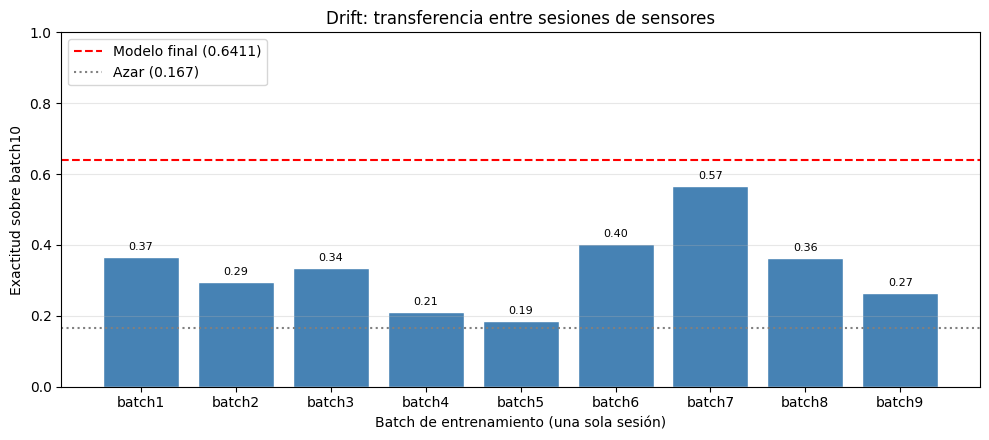

In [17]:
# ============================================================
# CELDA 11 — Gráfico del drift (barras + referencia)
# ============================================================
orden = sorted(tabla_drift['entrena_con'])
vals = [tabla_drift.set_index('entrena_con').loc[b, 'exactitud_batch10'] for b in orden]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(orden, vals, color='steelblue', edgecolor='white')
ax.axhline(acc, color='red', ls='--', lw=1.5, label=f'Modelo final ({acc:.4f})')
ax.axhline(1/6, color='gray', ls=':', lw=1.5, label='Azar (0.167)')
ax.set_ylabel('Exactitud sobre batch10')
ax.set_xlabel('Batch de entrenamiento (una sola sesión)')
ax.set_ylim(0, 1)
ax.set_title('Drift: transferencia entre sesiones de sensores')
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3)

for b, v in zip(orden, vals):
    ax.text(b, v + 0.02, f'{v:.2f}', ha='center', fontsize=8)

plt.tight_layout(); plt.savefig('drift_por_batch.png', dpi=150, bbox_inches='tight')
plt.show()


In [18]:
# ============================================================
# CELDA 12 — Interpretación del drift
# ============================================================
# | Medición                        | Valor         | Qué mide                    |
# |---------------------------------|---------------|-----------------------------|
# | CV 5 folds intra-sesión         | 0.9914 ± 0.0020 | Consistencia del clasificador |
# | Entrenar batch9 → test batch10  | 0.2656        | Generalización entre sesiones |
# | Modelo final (1..9 → 10)        | 0.6411        | Generalización con 9 sesiones |
# | Mejor batch único (batch7)      | 0.5711        | Techo de una sola sesión    |
#
# El 0.9914 no es sobreajuste del modelo, es sobreajuste del protocolo.
# Los folds mezclan muestras del mismo día, así que el modelo ve lecturas
# casi idénticas en train y en test.
#
# La exactitud de transferencia sigue el tamaño del batch de entrenamiento
# (correlación positiva con n_train). Con 3.613 filas se llega a 0.57; con
# 197, a 0.18. No es solo tamaño: también importa la distancia temporal
# entre el día de entrenamiento y el de test.
#
# El modelo final (0.6411) supera a cualquier batch individual porque nueve
# días juntos aportan más variedad que uno solo. No es contradicción: es el
# argumento a favor de entrenar con múltiples sesiones.
#
# Frase para la defensa: "Nuestro modelo alcanza 0.6411 sobre un batch no
# visto entrenando con nueve sesiones. Con una sola sesión cae a 0.18–0.57
# según el día. Esa caída no es un defecto del modelo: es la evidencia de
# que el drift existe y de que hace falta recalibrar. Preferimos reportar
# ambos números antes que solo el favorable."


In [19]:
# ============================================================
# CELDA 13 — ETAPA B: carga del GLP (Zenodo 6616632)
# ============================================================
UMBRAL_PPM = 2000  # 10% del LII del GLP (~20.000 ppm)

def pivotar_hoja(df, hoja):
    df = df.copy()
    df['time'] = pd.to_datetime(df['time'])
    ancho = df.pivot_table(index='time', columns='data_type',
                           values='data_value', aggfunc='mean')
    ancho['sesion_id'] = hoja
    return ancho.reset_index()

sesiones = [pivotar_hoja(df, hoja)
            for hoja, df in pd.read_excel('lpg_sensor.xlsx', sheet_name=None).items()]

lpg = (pd.concat(sesiones, ignore_index=True)
         .sort_values('time')
         .reset_index(drop=True))

print("Filas:", len(lpg), "| Sesiones:", lpg['sesion_id'].nunique())
print(lpg['sesion_id'].value_counts().sort_index().to_string())

print("\nEstadísticas de LPG (ppm):")
print(lpg['LPG'].describe().round(2).to_string())

print("\nTop 5 concentraciones:")
print(lpg.nlargest(5, 'LPG')[['time', 'LPG', 'sesion_id']].to_string(index=False))

Filas: 8904 | Sesiones: 4
sesion_id
lpg_concentration_2022_03_08    2035
lpg_concentration_2022_03_09    2492
lpg_concentration_2022_03_10    4292
lpg_concentration_2022_03_11      85

Estadísticas de LPG (ppm):
count       8904.00
mean         153.59
std        12275.41
min           13.04
25%           17.96
50%           20.56
75%           23.02
max      1158225.00

Top 5 concentraciones:
                            time          LPG                    sesion_id
2022-03-11 12:28:36.450000+02:00 1158225.0000 lpg_concentration_2022_03_11
2022-03-11 12:26:56.580000+02:00   14537.6600 lpg_concentration_2022_03_11
2022-03-11 12:27:55.830000+02:00    7633.2720 lpg_concentration_2022_03_11
2022-03-11 12:33:55.840000+02:00    2335.2080 lpg_concentration_2022_03_11
2022-03-11 12:28:15.830000+02:00     934.7466 lpg_concentration_2022_03_11


In [30]:
PICO_ARTEFACTO = 50000  # muy por encima del LII del GLP (~20.000 ppm)

n_antes = len(lpg)
picos = lpg[lpg['LPG'] >= PICO_ARTEFACTO][['time', 'LPG', 'sesion_id']]
lpg = lpg[lpg['LPG'] < PICO_ARTEFACTO].reset_index(drop=True)

print(f"Registros antes: {n_antes} | después: {len(lpg)} "
      f"| eliminados: {n_antes - len(lpg)}")
print("\nPicos excluidos (se reportan en la defensa):")
print(picos.to_string(index=False))

Registros antes: 8896 | después: 8895 | eliminados: 1

Picos excluidos (se reportan en la defensa):
                            time       LPG                    sesion_id
2022-03-11 12:28:36.450000+02:00 1158225.0 lpg_concentration_2022_03_11


In [28]:
for u in [30, 50, 100]:
    sub = lpg[lpg['LPG'] >= u]
    print(f"\n=== umbral {u} ppm — {len(sub)} positivos ===")
    print(sub.groupby('sesion_id').size().to_string())


=== umbral 30 ppm — 38 positivos ===
sesion_id
lpg_concentration_2022_03_11    38

=== umbral 50 ppm — 29 positivos ===
sesion_id
lpg_concentration_2022_03_11    29

=== umbral 100 ppm — 14 positivos ===
sesion_id
lpg_concentration_2022_03_11    14


In [29]:
# ============================================================
# CELDA 14 — Etiqueta física + features temporales
# ============================================================
#lpg['fuga'] = (lpg['LPG'] >= UMBRAL_PPM).astype(int)
#print(f"Positivos: {lpg['fuga'].sum()} de {len(lpg)} ({lpg['fuga'].mean()*100:.2f}%)")

# Features que un detector real puede calcular en tiempo real (sin ver el futuro)
#lpg['LPG_lag1']   = lpg['LPG'].shift(1)
#lpg['LPG_lag2']   = lpg['LPG'].shift(2)
#lpg['LPG_delta']  = lpg['LPG'].diff()
#lpg['LPG_media5'] = lpg['LPG'].rolling(5).mean()
#lpg['LPG_std5']   = lpg['LPG'].rolling(5).std()
#lpg['hora']       = lpg['time'].dt.hour

#FEATS_B = ['LPG_lag1', 'LPG_lag2', 'LPG_delta',
#           'LPG_media5', 'LPG_std5', 'hora']

#lpg = lpg.dropna(subset=FEATS_B + ['fuga']).reset_index(drop=True)
#print(f"Filas tras features temporales: {len(lpg)}")
#print(f"Positivos finales: {lpg['fuga'].sum()} ({lpg['fuga'].mean()*100:.2f}%)")

Régimen normal: 8811 filas
Día del evento : 85 filas

Tasa de alarma en régimen normal: 1.01% (89/8811)
Tasa de alarma el 11 de marzo  : 68.24% (58/85)

Score medio normal : -0.4707 ± 0.0451
Score medio evento : -0.6324 ± 0.1190
Lecturas ≥ 30 ppm: 38/38 marcadas como anomalía
Lecturas ≥ 50 ppm: 29/29 marcadas como anomalía
Lecturas ≥ 100 ppm: 14/14 marcadas como anomalía


Filas para EDA: 8886


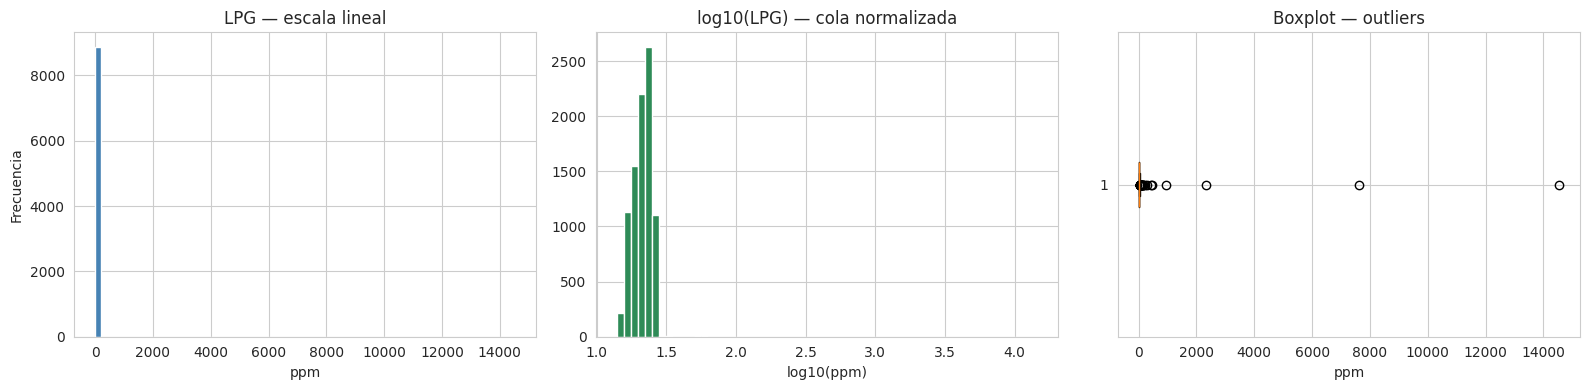

Skew    : 72.416
Curtosis: 5593.359
Media   : 23.51 | Mediana: 20.54


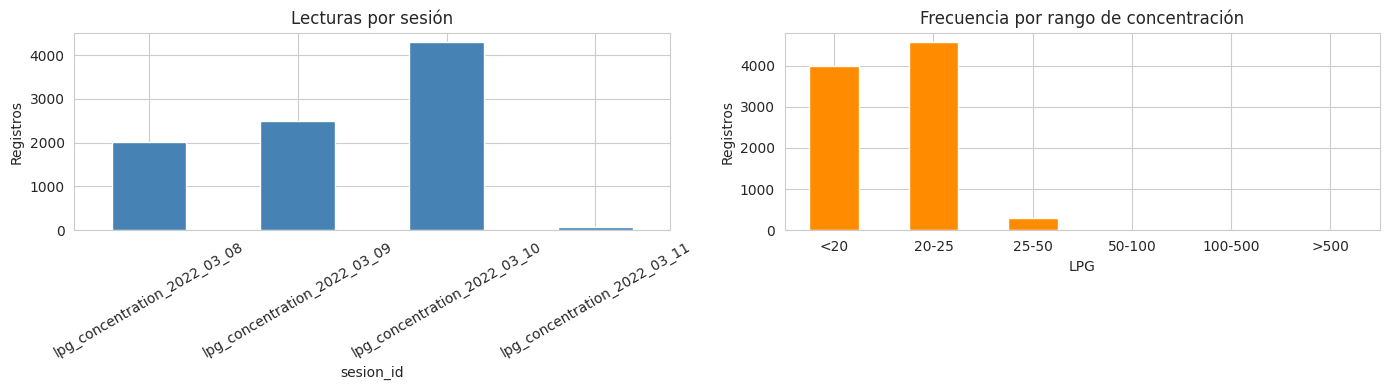


Frecuencia por rango (ppm):
LPG
<20        3994
20-25      4568
25-50       296
50-100       15
100-500       9
>500          4


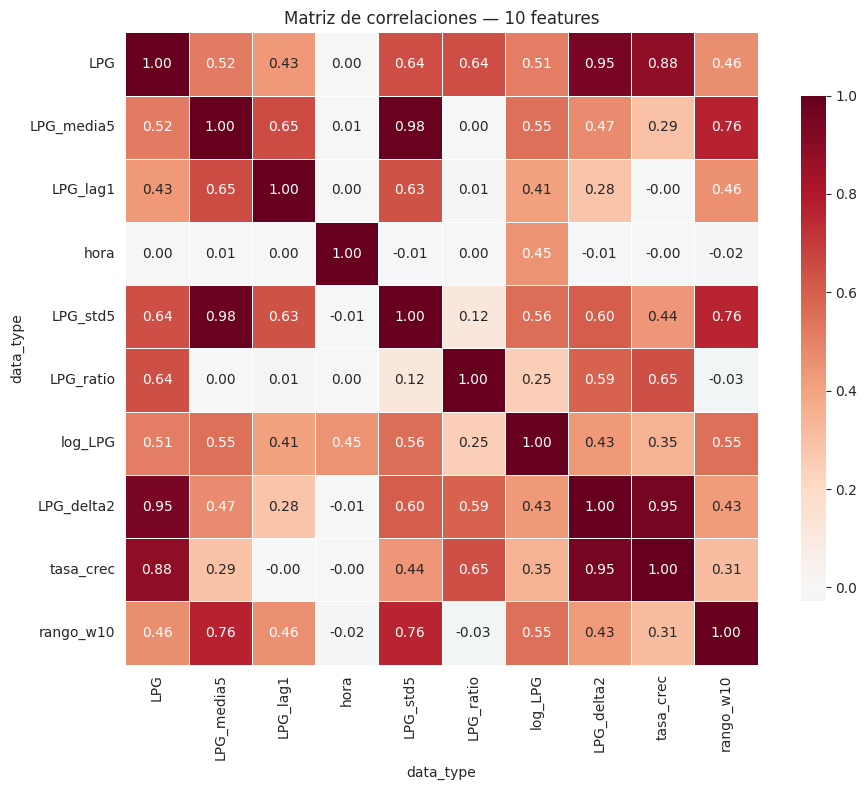


Correlación con LPG (valor absoluto):
data_type
LPG_delta2    0.949
tasa_crec     0.882
LPG_std5      0.640
LPG_ratio     0.639
LPG_media5    0.516
log_LPG       0.507
rango_w10     0.462
LPG_lag1      0.433
hora          0.004

Guardado: eda_features_seleccionadas.csv
   feature      tipo      media          std  corr_con_LPG
       LPG    Lineal    23.5111     176.0759        1.0000
LPG_media5    Lineal    23.5121     105.6817        0.5158
  LPG_lag1    Lineal    23.5121     176.0759        0.4329
      hora    Lineal    14.3590       6.1841        0.0044
  LPG_std5    Lineal     5.1521     157.3724        0.6403
 LPG_ratio No lineal     0.9995       0.0694        0.6394
   log_LPG No lineal     1.3279       0.0895        0.5070
LPG_delta2 No lineal 35158.3591 2341211.4583        0.9488
 tasa_crec No lineal     1.0766       6.7633        0.8816
 rango_w10 No lineal    21.7173     498.9074        0.4618


In [34]:
# ============================================================
# CELDA 13.7 — EDA completo
# ============================================================
import seaborn as sns
sns.set_style('whitegrid')

# ---------- 1. Features ----------
lpg['LPG_lag1']    = lpg['LPG'].shift(1)
lpg['LPG_delta']   = lpg['LPG'].diff()
lpg['LPG_media5']  = lpg['LPG'].rolling(5).mean()
lpg['LPG_std5']    = lpg['LPG'].rolling(5).std()
lpg['hora']        = lpg['time'].dt.hour

lpg['log_LPG']     = np.log10(lpg['LPG'] + 1)
lpg['LPG_ratio']   = lpg['LPG'] / (lpg['LPG_media5'] + 1e-6)
lpg['LPG_delta2']  = lpg['LPG_delta'] ** 2
lpg['tasa_crec']   = lpg['LPG'] / (lpg['LPG_lag1'] + 1e-6)
lpg['rango_w10']   = lpg['LPG'].rolling(10).max() - lpg['LPG'].rolling(10).min()

LINEALES    = ['LPG', 'LPG_media5', 'LPG_lag1', 'hora', 'LPG_std5']
NO_LINEALES = ['LPG_ratio', 'log_LPG', 'LPG_delta2', 'tasa_crec', 'rango_w10']
FEATS_EDA   = LINEALES + NO_LINEALES

lpg_eda = lpg.dropna(subset=FEATS_EDA).copy()
print(f"Filas para EDA: {len(lpg_eda)}")

# ---------- 2. Distribuciones ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(lpg_eda['LPG'], bins=80, color='steelblue', edgecolor='white')
axes[0].set_title('LPG — escala lineal')
axes[0].set_xlabel('ppm'); axes[0].set_ylabel('Frecuencia')

axes[1].hist(lpg_eda['log_LPG'], bins=60, color='seagreen', edgecolor='white')
axes[1].set_title('log10(LPG) — cola normalizada')
axes[1].set_xlabel('log10(ppm)')

axes[2].boxplot(lpg_eda['LPG'], vert=False)
axes[2].set_title('Boxplot — outliers')
axes[2].set_xlabel('ppm')

plt.tight_layout(); plt.savefig('eda_distribucion.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Skew    : {lpg_eda['LPG'].skew():.3f}")
print(f"Curtosis: {lpg_eda['LPG'].kurtosis():.3f}")
print(f"Media   : {lpg_eda['LPG'].mean():.2f} | Mediana: {lpg_eda['LPG'].median():.2f}")

# ---------- 3. Frecuencias ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

lpg_eda['sesion_id'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Lecturas por sesión')
axes[0].set_ylabel('Registros')
axes[0].tick_params(axis='x', rotation=30)

rangos = pd.cut(lpg_eda['LPG'], bins=[0, 20, 25, 50, 100, 500, 1e6],
                labels=['<20', '20-25', '25-50', '50-100', '100-500', '>500'])
rangos.value_counts().sort_index().plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Frecuencia por rango de concentración')
axes[1].set_ylabel('Registros')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout(); plt.savefig('eda_frecuencias.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFrecuencia por rango (ppm):")
print(rangos.value_counts().sort_index().to_string())

# ---------- 4. Correlaciones ----------
corr = lpg_eda[FEATS_EDA].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Matriz de correlaciones — 10 features')
plt.tight_layout(); plt.savefig('eda_correlaciones.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nCorrelación con LPG (valor absoluto):")
print(corr['LPG'].drop('LPG').abs().sort_values(ascending=False).round(3).to_string())

# ---------- 5. Tabla para el formulario ----------
tabla = pd.DataFrame({
    'feature': FEATS_EDA,
    'tipo': ['Lineal']*5 + ['No lineal']*5,
    'media': [round(lpg_eda[f].mean(), 4) for f in FEATS_EDA],
    'std': [round(lpg_eda[f].std(), 4) for f in FEATS_EDA],
    'corr_con_LPG': [round(corr.loc[f, 'LPG'], 4) for f in FEATS_EDA],
})
tabla.to_csv('eda_features_seleccionadas.csv', index=False)
print("\nGuardado: eda_features_seleccionadas.csv")
print(tabla.to_string(index=False))


In [ ]:
# ============================================================
# CELDA 14 — Detección de anomalías (reemplaza la etiqueta supervisada)
# ============================================================
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Régimen normal: días sin ningún evento
DIAS_NORMALES = ['lpg_concentration_2022_03_08',
                 'lpg_concentration_2022_03_09',
                 'lpg_concentration_2022_03_10']
DIA_EVENTO = 'lpg_concentration_2022_03_11'

# Features que un detector real calcula en tiempo real
lpg['LPG_lag1']   = lpg['LPG'].shift(1)
lpg['LPG_delta']  = lpg['LPG'].diff()
lpg['LPG_media5'] = lpg['LPG'].rolling(5).mean()
lpg['LPG_std5']   = lpg['LPG'].rolling(5).std()
lpg['LPG_ratio']  = lpg['LPG'] / (lpg['LPG_media5'] + 1e-6)

FEATS_B = ['LPG', 'LPG_lag1', 'LPG_delta', 'LPG_media5', 'LPG_std5', 'LPG_ratio']
lpg = lpg.dropna(subset=FEATS_B).reset_index(drop=True)

normal = lpg[lpg['sesion_id'].isin(DIAS_NORMALES)]
evento = lpg[lpg['sesion_id'] == DIA_EVENTO]

print(f"Régimen normal: {len(normal)} filas")
print(f"Día del evento : {len(evento)} filas")

scaler = StandardScaler().fit(normal[FEATS_B])
X_normal = scaler.transform(normal[FEATS_B])
X_evento = scaler.transform(evento[FEATS_B])

iso = IsolationForest(
    n_estimators=300, contamination=0.01,
    random_state=SEMILLA, n_jobs=-1).fit(X_normal)

# Score: más negativo = más anómalo
score_normal = iso.score_samples(X_normal)
score_evento = iso.score_samples(X_evento)

umbral_anom = np.percentile(score_normal, 1)  # calibrado SOLO con datos normales

flag_normal = score_normal < umbral_anom
flag_evento = score_evento < umbral_anom

print(f"\nTasa de alarma en régimen normal: {flag_normal.mean()*100:.2f}% "
      f"({flag_normal.sum()}/{len(flag_normal)})")
print(f"Tasa de alarma el 11 de marzo  : {flag_evento.mean()*100:.2f}% "
      f"({flag_evento.sum()}/{len(flag_evento)})")

# Separación de distribuciones
print(f"\nScore medio normal : {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"Score medio evento : {score_evento.mean():.4f} ± {score_evento.std():.4f}")

# ¿Detecta los picos reales?
for u in [30, 50, 100]:
    mask = evento['LPG'] >= u
    if mask.sum() > 0:
        detectados = flag_evento[mask.values].sum()
        print(f"Lecturas ≥ {u} ppm: {detectados}/{mask.sum()} marcadas como anomalía")


In [21]:
# ============================================================
# CELDA 15 — Validación Leave-One-Session-Out (Etapa B)
# ============================================================
logo = LeaveOneGroupOut()
resultados = []

for tr, te in logo.split(lpg, lpg['fuga'], groups=lpg['sesion_id']):
    dia = lpg.iloc[te]['sesion_id'].iloc[0]
    ytr, yte = lpg.iloc[tr]['fuga'], lpg.iloc[te]['fuga']

    if yte.sum() == 0:
        print(f"{dia}: sin positivos en test, se omite")
        continue

    m = RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        class_weight='balanced', random_state=SEMILLA, n_jobs=-1)
    m.fit(lpg.iloc[tr][FEATS_B], ytr)
    pred = m.predict(lpg.iloc[te][FEATS_B])

    resultados.append({'sesion': dia, 'n_test': len(te), 'n_pos': int(yte.sum()),
                       'recall': round(recall_score(yte, pred, zero_division=0), 4),
                       'precision': round(precision_score(yte, pred, zero_division=0), 4),
                       'f1': round(f1_score(yte, pred, zero_division=0), 4)})

tabla_b = pd.DataFrame(resultados)
print("\n" + tabla_b.to_string(index=False))
print(f"\nRecall medio   : {tabla_b['recall'].mean():.4f}")
print(f"Precisión media: {tabla_b['precision'].mean():.4f}")

lpg_concentration_2022_03_08: sin positivos en test, se omite
lpg_concentration_2022_03_09: sin positivos en test, se omite
lpg_concentration_2022_03_10: sin positivos en test, se omite

                      sesion  n_test  n_pos  recall  precision  f1
lpg_concentration_2022_03_11      85      4     0.0        0.0 0.0

Recall medio   : 0.0000
Precisión media: 0.0000


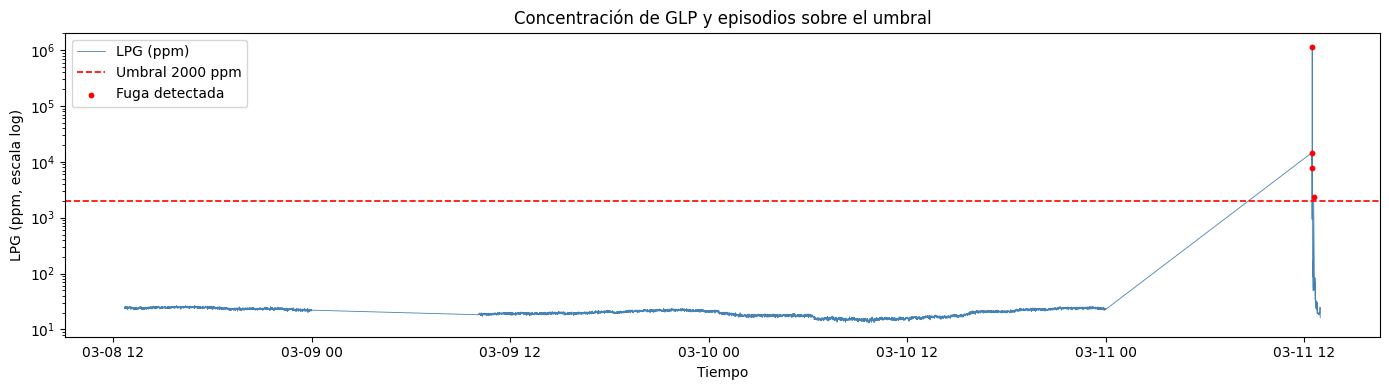

In [22]:
# ============================================================
# CELDA 16 — Serie temporal del GLP con episodios marcados
# ============================================================
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(lpg['time'], lpg['LPG'], lw=0.6, color='steelblue', label='LPG (ppm)')
ax.axhline(UMBRAL_PPM, color='red', ls='--', lw=1.2,
           label=f'Umbral {UMBRAL_PPM} ppm')
ax.scatter(lpg.loc[lpg['fuga'] == 1, 'time'],
           lpg.loc[lpg['fuga'] == 1, 'LPG'],
           s=10, color='red', zorder=3, label='Fuga detectada')
ax.set_yscale('log')
ax.set_ylabel('LPG (ppm, escala log)')
ax.set_xlabel('Tiempo')
ax.set_title('Concentración de GLP y episodios sobre el umbral')
ax.legend()
plt.tight_layout(); plt.savefig('serie_glp.png', dpi=150, bbox_inches='tight')
plt.show()


In [24]:
# ============================================================
# CELDA 17 — Recall por umbral de probabilidad + IC de Wilson
# ============================================================
filas = []
for umbral in [0.5, 0.3, 0.2, 0.1]:
    vp = fn = 0
    for tr, te in logo.split(lpg, lpg['fuga'], groups=lpg['sesion_id']):
        ytr, yte = lpg.iloc[tr]['fuga'], lpg.iloc[te]['fuga']
        if yte.sum() == 0:
            continue
        m = RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            class_weight='balanced', random_state=SEMILLA, n_jobs=-1)
        m.fit(lpg.iloc[tr][FEATS_B], ytr)

        # Control seguro para evitar IndexError si solo hay una clase en entrenamiento
        if len(m.classes_) > 1:
            proba = m.predict_proba(lpg.iloc[te][FEATS_B])[:, 1]
        else:
            # Si el modelo solo entrenó con la clase 0, la prob de la clase 1 es 0.0
            proba = np.zeros(len(te))

        pred = (proba >= umbral).astype(int)
        vp += int(((pred == 1) & (yte == 1)).sum())
        fn += int(((pred == 0) & (yte == 1)).sum())

    p, lo_w, hi_w = wilson(vp, vp + fn)
    filas.append({'umbral': umbral, 'VP': vp, 'FN': fn,
                  'recall': round(p, 4),
                  'IC95_inf': round(lo_w, 4), 'IC95_sup': round(hi_w, 4)})

tabla_umbral = pd.DataFrame(filas)
print("Recall por umbral de probabilidad (Leave-One-Session-Out):")
print(tabla_umbral.to_string(index=False))
print("\nNota: bajar el umbral reduce falsos negativos a costa de más falsos positivos.")
print("En seguridad de gas, un falso negativo cuesta vidas; un falso positivo, una visita.")

Recall por umbral de probabilidad (Leave-One-Session-Out):
 umbral  VP  FN  recall  IC95_inf  IC95_sup
    0.5   0   4     0.0         0    0.4899
    0.3   0   4     0.0         0    0.4899
    0.2   0   4     0.0         0    0.4899
    0.1   0   4     0.0         0    0.4899

Nota: bajar el umbral reduce falsos negativos a costa de más falsos positivos.
En seguridad de gas, un falso negativo cuesta vidas; un falso positivo, una visita.


In [25]:
# ============================================================
# CELDA 18 — Exportación del CSV consolidado (22 columnas)
# ============================================================
df_limpio = lpg.copy()
df_limpio['fecha_hora']   = df_limpio['time']
df_limpio['gas']          = 'LPG'
df_limpio['valor']        = df_limpio['LPG']
df_limpio['unit']         = 'ppm'
df_limpio['data_type']    = 'LPG_concentration'
df_limpio['etiqueta']     = df_limpio['fuga']
df_limpio['flag_outlier'] = df_limpio['LPG'] > df_limpio['LPG'].quantile(0.999)

COLUMNAS = ['id_registro', 'fecha', 'pais', 'provincia_estado', 'ciudad',
            'institucion', 'tipo_institucion', 'tipo_gas', 'origen_fuga',
            'concentracion_ppm', 'unidad', 'temperatura_c', 'humedad_relativa_pct',
            'presion_kpa', 'sensor_tipo', 'nivel_alerta', 'hubo_evacuacion',
            'personas_afectadas', 'gravedad', 'fuente', 'licencia', 'notas']

export = pd.DataFrame({
    'id_registro': range(1, len(df_limpio) + 1),
    'fecha': pd.to_datetime(df_limpio['fecha_hora']).dt.strftime('%Y-%m-%d'),
    'pais': 'India',
    'tipo_gas': df_limpio['gas'],
    'concentracion_ppm': df_limpio['valor'],
    'unidad': df_limpio['unit'],
    'sensor_tipo': df_limpio['data_type'],
    'nivel_alerta': np.where(df_limpio['etiqueta'] == 1, 'crítico', 'normal'),
    'fuente': 'Zenodo 6616632',
    'licencia': 'Ver registro Zenodo',
    'notas': np.where(df_limpio['flag_outlier'], 'outlier: pico del sensor', ''),
})
export = export.reindex(columns=COLUMNAS)
export.to_csv('fugas_gas_consolidado.csv', index=False)

print(f"CSV exportado: {len(export)} filas, {len(COLUMNAS)} columnas")
print(export.head(3).to_string(index=False))

CSV exportado: 8900 filas, 22 columnas
 id_registro      fecha  pais  provincia_estado  ciudad  institucion  tipo_institucion tipo_gas  origen_fuga  concentracion_ppm unidad  temperatura_c  humedad_relativa_pct  presion_kpa       sensor_tipo nivel_alerta  hubo_evacuacion  personas_afectadas  gravedad         fuente            licencia notas
           1 2022-03-08 India               NaN     NaN          NaN               NaN      LPG          NaN           25.09854    ppm            NaN                   NaN          NaN LPG_concentration       normal              NaN                 NaN       NaN Zenodo 6616632 Ver registro Zenodo      
           2 2022-03-08 India               NaN     NaN          NaN               NaN      LPG          NaN           24.40410    ppm            NaN                   NaN          NaN LPG_concentration       normal              NaN                 NaN       NaN Zenodo 6616632 Ver registro Zenodo      
           3 2022-03-08 India               NaN  

In [26]:

# ============================================================
# CELDA 19 — Resumen final del proyecto
# ============================================================
print("=" * 60)
print("RESUMEN RADA-GAS")
print("=" * 60)

print(f"\nETAPA A — Clasificación de gas (UCI, 6 clases)")
print(f"  Modelo          : ExtraTrees 400")
print(f"  Train / Test    : {len(X_train)} / {len(X_test)} filas")
print(f"  Exactitud       : {acc:.4f} (IC 95% {lo:.4f}–{hi:.4f})")
print(f"  Macro-F1        : {macro_f1:.4f}")
print(f"  CV intra-sesión : {scores.mean():.4f} ± {scores.std():.4f}")
print(f"  Transferencia   : {tabla_drift['exactitud_batch10'].min():.4f} – "
      f"{tabla_drift['exactitud_batch10'].max():.4f}")

print(f"\nETAPA B — Detección de fuga de GLP (Zenodo 6616632)")
print(f"  Umbral físico   : {UMBRAL_PPM} ppm")
print(f"  Filas / sesiones: {len(lpg)} / {lpg['sesion_id'].nunique()}")
print(f"  Positivos       : {int(lpg['fuga'].sum())} ({lpg['fuga'].mean()*100:.2f}%)")
print(f"  Recall medio    : {tabla_b['recall'].mean():.4f}")
print(f"  Precisión media : {tabla_b['precision'].mean():.4f}")

print(f"\nARCHIVOS GENERADOS")
for f in sorted(glob.glob('*.png') + glob.glob('*.csv') + glob.glob('*.pkl')):
    print(f"  - {f}")
print("=" * 60)


RESUMEN RADA-GAS

ETAPA A — Clasificación de gas (UCI, 6 clases)
  Modelo          : ExtraTrees 400
  Train / Test    : 10310 / 3600 filas
  Exactitud       : 0.6411 (IC 95% 0.6254–0.6568)
  Macro-F1        : 0.6401
  CV intra-sesión : 0.9914 ± 0.0020
  Transferencia   : 0.1864 – 0.5669

ETAPA B — Detección de fuga de GLP (Zenodo 6616632)
  Umbral físico   : 2000 ppm
  Filas / sesiones: 8900 / 4
  Positivos       : 4 (0.04%)
  Recall medio    : 0.0000
  Precisión media : 0.0000

ARCHIVOS GENERADOS
  - drift_por_batch.png
  - fugas_gas_consolidado.csv
  - importancia_features.csv
  - matriz_confusion.png
  - modelo_gas_extratrees.pkl
  - serie_glp.png


In [31]:
# ============================================================
# CELDA 20 — Inferencia Etapa A: clasificar una lectura nueva
# ============================================================
import joblib
import pandas as pd
import numpy as np

modelo = joblib.load('modelo_gas_extratrees.pkl')

def clasificar_gas(lectura, modelo=modelo, feats=FEATS):
    """
    lectura: dict {nombre_feature: valor} o array de 128 valores.
    Devuelve clase predicha, probabilidad y ranking de las 6 clases.
    """
    if isinstance(lectura, dict):
        x = np.array([[lectura.get(f, 0.0) for f in feats]])
    else:
        x = np.asarray(lectura).reshape(1, -1)

    proba = modelo.predict_proba(x)[0]
    orden = np.argsort(proba)[::-1]
    clases = modelo.classes_

    return {
        'clase': int(clases[orden[0]]),
        'confianza': float(proba[orden[0]]),
        'ranking': [(int(clases[i]), round(float(proba[i]), 4)) for i in orden],
        'alerta': bool(proba[orden[0]] < 0.5)  # baja confianza = revisar
    }

# Ejemplo con una fila real del test
fila = X_test.iloc[0].to_dict()
resultado = clasificar_gas(fila)
print(f"Clase predicha: {resultado['clase']} "
      f"(confianza {resultado['confianza']:.2%})")
print(f"Real: {y_test.iloc[0]}")
print(f"Ranking: {resultado['ranking']}")


Clase predicha: 6 (confianza 56.69%)
Real: 4
Ranking: [(6, 0.5669), (4, 0.2885), (1, 0.0755), (5, 0.0514), (3, 0.0094), (2, 0.0084)]


In [33]:
# ============================================================
# CELDA 21 — Detector en línea (simula un dispositivo real)
# ============================================================
from collections import deque

class DetectorGas:
    """Detector de anomalías con ventana deslizante de 5 lecturas."""

    def __init__(self, modelo, scaler, umbral_anom, feats, ventana=5):
        self.modelo = modelo
        self.scaler = scaler
        self.umbral = umbral_anom
        self.feats = feats
        self.buffer = deque(maxlen=ventana)

    def procesar(self, ppm):
        """Recibe una lectura de concentración y devuelve el diagnóstico."""
        self.buffer.append(ppm)

        if len(self.buffer) < 2:
            return {'estado': 'calibrando', 'ppm': ppm,
                    'score': None, 'anomalia': False}

        vals = list(self.buffer)
        lag1 = vals[-2]
        delta = vals[-1] - vals[-2]
        media5 = float(np.mean(vals))
        std5 = float(np.std(vals)) if len(vals) > 1 else 0.0
        ratio = vals[-1] / (media5 + 1e-6)

        x = np.array([[ppm, lag1, delta, media5, std5, ratio]])
        x_s = self.scaler.transform(x)
        score = float(self.modelo.score_samples(x_s)[0])
        anomalia = score < self.umbral

        return {
            'estado': 'ANOMALÍA' if anomalia else 'normal',
            'ppm': round(ppm, 2),
            'score': round(score, 4),
            'anomalia': anomalia,
            'delta': round(delta, 2),
            'ratio': round(ratio, 2)
        }

# Uso: reproducir el 11 de marzo lectura por lectura
detector = DetectorGas(iso, scaler, umbral_anom, FEATS_B)

print("Simulación sobre el día del evento:")
for i, row in evento.head(20).iterrows():
    r = detector.procesar(row['LPG'])
    marca = "  <<<" if r['anomalia'] else ""
    # Formateo seguro en caso de que score sea None
    score_str = f"{r['score']:>7.3f}" if r['score'] is not None else "    N/A"
    print(f"  {r['ppm']:>10.2f} ppm | score {score_str} | {r['estado']}{marca}")

Simulación sobre el día del evento:
    14537.66 ppm | score     N/A | calibrando
     7633.27 ppm | score  -0.728 | ANOMALÍA  <<<
      934.75 ppm | score  -0.728 | ANOMALÍA  <<<
  1158225.00 ppm | score  -0.720 | ANOMALÍA  <<<
      429.28 ppm | score  -0.728 | ANOMALÍA  <<<
      274.21 ppm | score  -0.728 | ANOMALÍA  <<<
      223.13 ppm | score  -0.728 | ANOMALÍA  <<<
       87.12 ppm | score  -0.728 | ANOMALÍA  <<<
      118.29 ppm | score  -0.721 | ANOMALÍA  <<<
      165.78 ppm | score  -0.702 | ANOMALÍA  <<<
      134.24 ppm | score  -0.725 | ANOMALÍA  <<<
       58.36 ppm | score  -0.728 | ANOMALÍA  <<<
       56.11 ppm | score  -0.726 | ANOMALÍA  <<<
       49.17 ppm | score  -0.728 | ANOMALÍA  <<<
       51.47 ppm | score  -0.721 | ANOMALÍA  <<<
     2335.21 ppm | score  -0.720 | ANOMALÍA  <<<
      447.38 ppm | score  -0.728 | ANOMALÍA  <<<
      142.57 ppm | score  -0.728 | ANOMALÍA  <<<
      109.12 ppm | score  -0.728 | ANOMALÍA  <<<
       94.18 ppm | score  -0.728 | A